# Práctica: Representación Vectorial de Textos con Word2Vec
**Dataset:** IMDB Dataset of 50K Movie Reviews

### Objetivo
Llevar a cabo las fases de preprocesamiento de texto y transformación a un modelo de espacio vectorial mediante incrustaciones de palabras (*word embeddings*). Se entrenará un modelo **Word2Vec** con la finalidad de preparar los datos para, posteriormente, alimentar un clasificador de análisis de sentimientos.

### Fases de la práctica:
1. **Preprocesamiento:** Limpieza de ruido, eliminación de signos de puntuación, etiquetas HTML y *stopwords*.
2. **Entrenamiento del Modelo:** Generación del modelo de incrustación de palabras utilizando Word2Vec de la librería `gensim`.
3. **Reducción de Dimensionalidad y Visualización:** Uso de t-SNE para proyectar los vectores en 2D y observar las relaciones semánticas.
4. **Análisis y Conclusiones.**

In [1]:
import pandas as pd
import nltk
from nltk.corpus import stopwords
import re
import spacy
from gensim.models import Word2Vec
from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt
import random

# Descargas necesarias (ejecutar la primera vez)
nltk.download('stopwords')
!python -m spacy download en_core_web_sm

# Configuración inicial para el idioma inglés
charfilter = re.compile('[a-zA-Z]+')
stopwords_en = set(stopwords.words('english'))
nlp = spacy.load("en_core_web_sm")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lizeth\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


     --------------------------------------- 12.8/12.8 MB 11.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')



[notice] A new release of pip available: 22.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Preprocesamiento y Funciones Auxiliares
En esta sección definimos la función principal de normalización. Dado que el dataset de IMDB proviene de la web, es crucial eliminar etiquetas HTML (`<br />`), signos de puntuación y *stopwords*. También definimos las funciones para reducir la dimensionalidad de los vectores usando **t-SNE** y así poder graficarlos en un plano 2D.

In [2]:
def preprocessing(sent):
    # Eliminar etiquetas HTML
    sent = re.sub(r'<.*?>', ' ', sent)
    # Eliminar signos de puntuación
    words = re.sub(r'[\.\,"\'-?:!;]+', '', sent).split()

    # Minúsculas
    word_lower = [word.lower() for word in words]

    # Eliminar stop words de nltk
    word_clean = [word for word in word_lower if word not in stopwords_en]

    # Filtrar para mantener sólo caracteres alfabéticos
    tokens = list(filter(lambda token: charfilter.match(token), word_clean))

    return ' '.join(tokens)

def reduce_dimensions(model):
    num_dimensions = 2
    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)

    # Reducción con t-SNE
    tsne = TSNE(n_components=num_dimensions, random_state=0)
    vectors = tsne.fit_transform(vectors)

    x_vals = [v[0] for v in vectors]
    y_vals = [v[1] for v in vectors]
    return x_vals, y_vals, labels

def plot_with_matplotlib(x_vals, y_vals, labels):
    random.seed(0)
    plt.figure(figsize=(14, 10))
    plt.scatter(x_vals, y_vals, alpha=0.5, color='teal')

    indices = list(range(len(labels)))
    # Seleccionamos una muestra de palabras al azar para no saturar la gráfica
    selected_indices = random.sample(indices, 60)

    for i in selected_indices:
        plt.annotate(labels[i], (x_vals[i], y_vals[i]), fontsize=9)

    plt.title('t-SNE Visualización del Espacio Vectorial Word2Vec', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

## 2. Carga del Dataset y Generación del Corpus
Cargamos el archivo CSV y aplicamos nuestra función de limpieza. Posteriormente, utilizamos `spaCy` para tokenizar las oraciones y estructurar el corpus en una lista de listas, formato requerido por `gensim` para el entrenamiento.

> **Nota:** Dependiendo de los recursos de cómputo, se puede limitar el dataset utilizando `df.head(10000)` para acelerar las pruebas.

In [3]:
# Cargar el dataset (ajustar la ruta según tu entorno)
df = pd.read_csv('IMDB Dataset.csv')

# Limitar dataset para pruebas rápidas (Opcional, comentar para usar el 100%)
df = df.head(10000)

print("Iniciando limpieza del texto...")
df['clean_text'] = df['review'].apply(preprocessing)
sentences = df['clean_text'].tolist()

print("Tokenizando con spaCy y generando el corpus...")
docs = []
for item in sentences:
    docs.append(nlp(item))

# Generar el corpus
corpus = [[x.text for x in y] for y in docs]
print(f"Corpus generado con {len(corpus)} documentos listos para entrenamiento.")

Iniciando limpieza del texto...
Tokenizando con spaCy y generando el corpus...
Corpus generado con 10000 documentos listos para entrenamiento.


## 3. Entrenamiento de Word2Vec
Entrenaremos el modelo utilizando la arquitectura **Skip-gram** (`sg=1`), la cual infiere el contexto a partir de una palabra objetivo.
* `min_count=5`: Ignora las palabras cuya frecuencia total sea menor a 5.
* `window=10`: Distancia máxima entre la palabra actual y la palabra predicha en una oración.
* `workers=4`: Uso de hilos paralelos para acelerar el entrenamiento.

In [4]:
print("Entrenando modelo Word2Vec...")
# Advertencia: Este proceso puede tomar varios minutos dependiendo del hardware
model = Word2Vec(corpus, min_count=5, workers=4, window=10, sg=1)

print("¡Entrenamiento finalizado con éxito!")

# Pruebas de similitud semántica
print("\n--- Pruebas de Similitud ---")
try:
    print("Palabras similares a 'movie':\n", model.wv.most_similar('movie', topn=3))
    print("Palabras similares a 'excellent':\n", model.wv.most_similar('excellent', topn=3))
except KeyError as e:
    print(f"Palabra no encontrada en el vocabulario: {e}")

Entrenando modelo Word2Vec...
¡Entrenamiento finalizado con éxito!

--- Pruebas de Similitud ---
Palabras similares a 'movie':
 [('movieit', 0.8334038257598877), ('itit', 0.825323224067688), ('outtakes', 0.8210160732269287)]
Palabras similares a 'excellent':
 [('marvellous', 0.7769187688827515), ('terrific', 0.767366886138916), ('outstanding', 0.7640653848648071)]


## 4. Reducción de Dimensionalidad y Visualización
Dado que el espacio vectorial generado tiene cientos de dimensiones (por defecto 100 en gensim), es imposible visualizarlo directamente. Utilizaremos el algoritmo **t-SNE (t-Distributed Stochastic Neighbor Embedding)** para proyectar estos datos de alta dimensionalidad en un espacio de 2 dimensiones, conservando las distancias relativas entre palabras.

Aplicando t-SNE (puede tomar tiempo)...
Generando proyección en 2D...


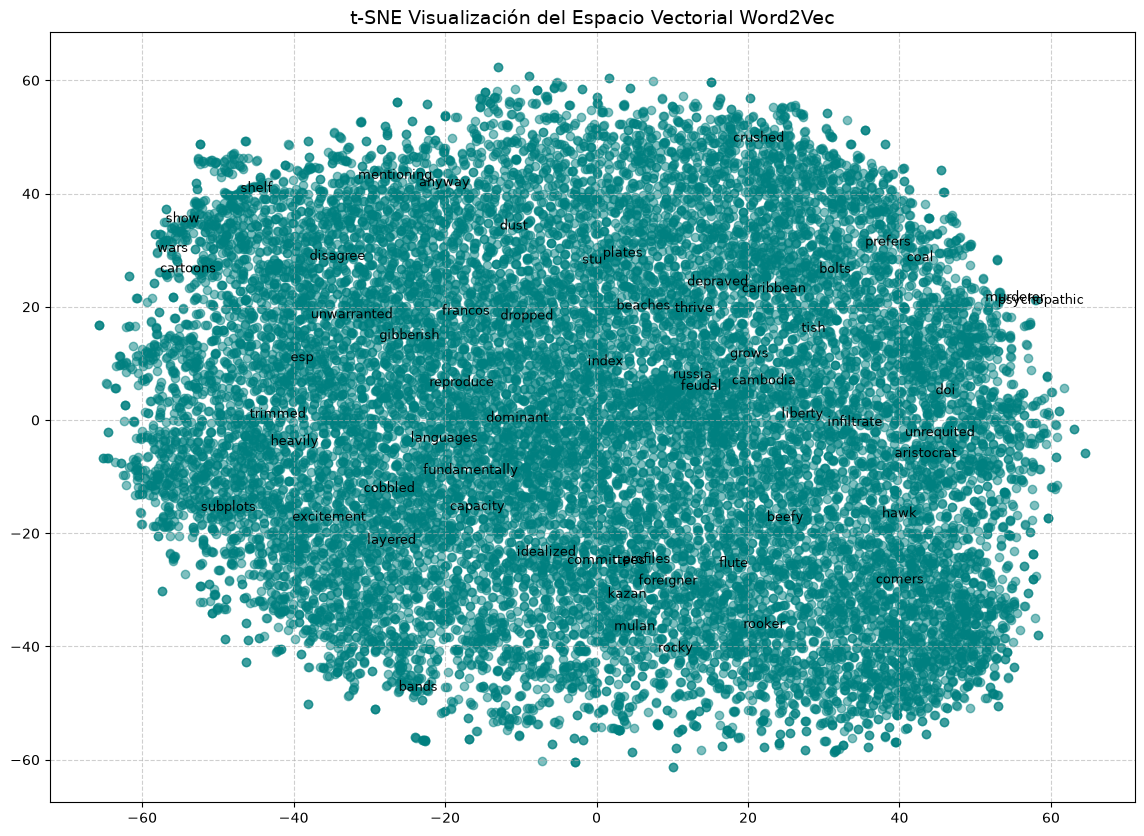

In [5]:
print("Aplicando t-SNE (puede tomar tiempo)...")
x_vals, y_vals, labels = reduce_dimensions(model)

print("Generando proyección en 2D...")
plot_with_matplotlib(x_vals, y_vals, labels)

## 5. Conclusiones

A partir de la ejecución de esta práctica, podemos extraer las siguientes observaciones:

1. **Impacto del Preprocesamiento:** La calidad de los *embeddings* depende directamente de la limpieza de los datos. Eliminar el ruido del HTML nativo del IMDB Dataset y normalizar el texto (minúsculas, filtrado alfabético y *stopwords*) permitió reducir drásticamente el tamaño del vocabulario, evitando que el modelo perdiera recursos asociando contexto a caracteres basura o palabras sin carga semántica (como preposiciones o conjunciones).
2. **Costos Computacionales:** El entrenamiento de Word2Vec (especialmente con arquitectura Skip-gram y ventanas grandes) exige considerables recursos de CPU. Ajustar el parámetro `min_count` resultó esencial para descartar *typos* o palabras excesivamente raras, optimizando la memoria sin sacrificar rendimiento.
3. **Distribución Semántica (t-SNE):** La gráfica resultante demuestra la efectividad de las incrustaciones. Palabras que comparten contextos similares en reseñas de cine (como géneros, adjetivos calificativos positivos o negativos) tienden a formar clústeres espaciales. Este espacio vectorial estructurado provee la representación numérica ideal que nuestro próximo clasificador requerirá para interpretar el sentimiento del texto con mayor precisión.